In [10]:
import pandas as pd


In [11]:
#load the dataset
df  = pd.read_csv("C:\\Users\\felix\Desktop\\models\\Churn-model\\Telco-Customer-Churn.csv")
print("shape:" ,df.shape)
print("first five: ",df.head(2))
df.info()

<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
<>:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
C:\Users\felix\AppData\Local\Temp\ipykernel_13272\4267470339.py:2: SyntaxWarning: "\D" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\D"? A raw string is also an option.
  df  = pd.read_csv("C:\\Users\\felix\Desktop\\models\\Churn-model\\Telco-Customer-Churn.csv")


shape: (7043, 21)
first five:     customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   

  TechSupport StreamingTV StreamingMovies        Contract PaperlessBilling  \
0          No          No              No  Month-to-month              Yes   
1          No          No              No        One year               No   

      PaymentMethod MonthlyCharges  TotalCharges Churn  
0  Electronic check          29.85         29.85    No  
1      Mailed check          56.95        1889.5    No  

[2 rows x 21 columns]
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data co

In [12]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True) * 100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [13]:
print("missing Values:")
print(df.isnull().sum())

print("\nTotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nBlank TotalCharges values:")
print((df["TotalCharges"].str.strip() == "").sum())

missing Values:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

TotalCharges data type:
str

Blank TotalCharges values:
11


In [14]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("Missing TotalCharges after conversion:")
print(df["TotalCharges"].isnull().sum())

print(df[df["TotalCharges"].isnull()][["tenure", "MonthlyCharges", "TotalCharges"]])

Missing TotalCharges after conversion:
11
      tenure  MonthlyCharges  TotalCharges
488        0           52.55           NaN
753        0           20.25           NaN
936        0           80.85           NaN
1082       0           25.75           NaN
1340       0           56.05           NaN
3331       0           19.85           NaN
3826       0           25.35           NaN
4380       0           20.00           NaN
5218       0           19.70           NaN
6670       0           73.35           NaN
6754       0           61.90           NaN


In [15]:
#remove records with missing Total charges
df = df.dropna(subset=["TotalCharges"])

print("Dataset shape after cleaning:", df.shape)
print("Missing values remaining:", df.isnull().sum().sum())

Dataset shape after cleaning: (7032, 21)
Missing values remaining: 0


In [16]:
print(df.columns.tolist())

['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


In [17]:
#the input feature
X = df.drop(columns = ["Churn", "customerID"])
#the target to we predict
y = df["Churn"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget examples:")
print(y.head())

Feature shape: (7032, 19)
Target shape: (7032,)

Target examples:
0     No
1     No
2    Yes
3     No
4    Yes
Name: Churn, dtype: str


In [18]:
#split the data before the preprocessing of encording the categorical 

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    random_state=42,
    test_size=0.2,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

Training features: (5625, 19)
Testing features: (1407, 19)

Training target distribution:
Churn
No     0.734222
Yes    0.265778
Name: proportion, dtype: float64

Testing target distribution:
Churn
No     0.734186
Yes    0.265814
Name: proportion, dtype: float64


In [19]:
#identifying categorical feature

categorical_features = X_train.select_dtypes(
    include=["str", "object", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include = ['number']
).columns.tolist()

print("Categorical features:", categorical_features)
print("Number of Categorical features:", len(categorical_features))

print("numerical features:", numerical_features)
print("Number of numerical features:", len(numerical_features))

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Number of Categorical features: 15
numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Number of numerical features: 4


In [20]:
#encoding libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers =[(
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )],
    remainder = "passthrough"
)


In [21]:
#training the model from training data

X_train_encoded = preprocessor.fit_transform(X_train)

#transform test data using the same fitted method
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:" , X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (5625, 45)
Encoded testing shape: (1407, 45)


In [22]:
print("Original categorical data:")
print(X_train[categorical_features].head(2))

Original categorical data:
     gender Partner Dependents PhoneService     MultipleLines InternetService  \
1413   Male     Yes        Yes          Yes               Yes     Fiber optic   
7003   Male      No         No           No  No phone service             DSL   

     OnlineSecurity OnlineBackup DeviceProtection TechSupport StreamingTV  \
1413            Yes          Yes              Yes         Yes          No   
7003             No           No              Yes         Yes          No   

     StreamingMovies        Contract PaperlessBilling            PaymentMethod  
1413              No        Two year               No  Credit card (automatic)  
7003              No  Month-to-month               No         Electronic check  


In [23]:
#to see the encoded one
encoded_columns = preprocessor.get_feature_names_out()
print("Encoded columns names:")
print(encoded_columns)

print("\nFirst 5 endoded records:")
print(X_train_encoded[:5])



Encoded columns names:
['categorical__gender_Female' 'categorical__gender_Male'
 'categorical__Partner_No' 'categorical__Partner_Yes'
 'categorical__Dependents_No' 'categorical__Dependents_Yes'
 'categorical__PhoneService_No' 'categorical__PhoneService_Yes'
 'categorical__MultipleLines_No'
 'categorical__MultipleLines_No phone service'
 'categorical__MultipleLines_Yes' 'categorical__InternetService_DSL'
 'categorical__InternetService_Fiber optic'
 'categorical__InternetService_No' 'categorical__OnlineSecurity_No'
 'categorical__OnlineSecurity_No internet service'
 'categorical__OnlineSecurity_Yes' 'categorical__OnlineBackup_No'
 'categorical__OnlineBackup_No internet service'
 'categorical__OnlineBackup_Yes' 'categorical__DeviceProtection_No'
 'categorical__DeviceProtection_No internet service'
 'categorical__DeviceProtection_Yes' 'categorical__TechSupport_No'
 'categorical__TechSupport_No internet service'
 'categorical__TechSupport_Yes' 'categorical__StreamingTV_No'
 'categorical__St

In [24]:
#designing a decision tree model to predict the churn 
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=5, random_state=42)
model.fit(X_train_encoded, y_train)
print("model training completed")
# the fit methods learns the pattern from the encoded training feature and there corresponding chun lable

model training completed


In [25]:
#Model prediction
y_pred= model.predict(X_test_encoded)

print("First 10 actual outcomes:")
print("y_test data:",y_test.head(10).tolist())

print("\nFirst 10 predicted outcomes:")
print("The predicted values:", y_pred[:10])

First 10 actual outcomes:
y_test data: ['No', 'No', 'No', 'Yes', 'No', 'Yes', 'No', 'No', 'Yes', 'No']

First 10 predicted outcomes:
The predicted values: ['No' 'Yes' 'No' 'No' 'No' 'No' 'No' 'No' 'Yes' 'No']


In [26]:
#we evaluate with the model using the confussion metrics
from sklearn.metrics import(accuracy_score,confusion_matrix,classification_report)

print("Accuracy:",accuracy_score(y_test,y_pred))

print("\nConfussion Matrix:")
print(confusion_matrix(y_test,y_pred))

print("\nClassfication Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.7896233120113717

Confussion Matrix:
[[881 152]
 [144 230]]

Classfication Report:
              precision    recall  f1-score   support

          No       0.86      0.85      0.86      1033
         Yes       0.60      0.61      0.61       374

    accuracy                           0.79      1407
   macro avg       0.73      0.73      0.73      1407
weighted avg       0.79      0.79      0.79      1407



In [27]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import make_scorer,recall_score


#define lables

churn_recall = make_scorer(
    recall_score,
    pos_label ="Yes"
)


depths = [3,5,7,10,15]

for depth in depths:
    model_cv = DecisionTreeClassifier(
        max_depth = depth,
        random_state= 42

    )

    scores = cross_val_score(
        model_cv,
        X_train_encoded,
        y_train,
        cv=5,
        scoring = churn_recall,
        n_jobs = -1
        )
    print(
        f"Depth: {depth:2d} | " 
        f"mean recall: :{scores.mean():.3f} | "
        f"std: {scores.std():.3f}"
          
          
          )

Depth:  3 | mean recall: :0.369 | std: 0.029
Depth:  5 | mean recall: :0.542 | std: 0.069
Depth:  7 | mean recall: :0.551 | std: 0.069
Depth: 10 | mean recall: :0.543 | std: 0.038
Depth: 15 | mean recall: :0.520 | std: 0.024


In [28]:
#examine the precision so as to know realy how many incorectly flags were made
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix

best_model = DecisionTreeClassifier(
    max_depth= 7,
    random_state=42
)
best_model.fit(X_train_encoded, y_train)

y_pred_best = best_model.predict(X_test_encoded)

print("confusion matrix:")
print(confusion_matrix(y_test,y_pred_best))

print("\nClassfication Report:")
print(classification_report(y_test,y_pred_best))

confusion matrix:
[[898 135]
 [178 196]]

Classfication Report:
              precision    recall  f1-score   support

          No       0.83      0.87      0.85      1033
         Yes       0.59      0.52      0.56       374

    accuracy                           0.78      1407
   macro avg       0.71      0.70      0.70      1407
weighted avg       0.77      0.78      0.77      1407



In [29]:
#lets use the algorithmn for random forest for the good generalization
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state= 42,
    class_weight = "balanced",
    n_jobs =-1

)
rf_model.fit(X_train_encoded,y_train)
y_pred_rf = rf_model.predict(X_test_encoded)

print("confusion matrix:")
print(confusion_matrix(y_test, y_pred_rf))

print("\nClassification report:")
print(classification_report(y_test,y_pred_rf))

confusion matrix:
[[832 201]
 [135 239]]

Classification report:
              precision    recall  f1-score   support

          No       0.86      0.81      0.83      1033
         Yes       0.54      0.64      0.59       374

    accuracy                           0.76      1407
   macro avg       0.70      0.72      0.71      1407
weighted avg       0.78      0.76      0.77      1407



In [30]:
#on businedd rules lets create a pipeline so that every algorithm learn by avoiding inf from validatio
# fold from influencing preprocessing,, aldo data leakage

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [31]:
#preprocess categorical features

preprocessor = ColumnTransformer(
    transformers=[(
        "categorical",
        OneHotEncoder(handle_unknown="ignore"),
        categorical_features
    )],
    remainder="passthrough"
)

#Decision tree
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",DecisionTreeClassifier(
        max_depth= 7,
        random_state= 42
    ))

])

#Decision tree
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier",RandomForestClassifier(
        n_estimators = 200,
        class_weight = "balanced",
        n_jobs = 1,
        random_state= 42
    ))

])
print("Both Pipelines created successfully.")






Both Pipelines created successfully.


In [32]:
#Validate the score for both pipelines
from sklearn.model_selection import cross_validate
from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        pos_label="Yes"
    ),
    "recall": make_scorer(
        recall_score,
        pos_label="Yes"
    ),
    "f1": make_scorer(
        f1_score,
        pos_label="Yes",
        zero_division=0
    )
}
models= {
    "Decision Tree": dt_pipeline,
    "Random Forest": rf_pipeline
}

for name,pipeline in models.items():
    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=5,
        scoring = scoring,
        n_jobs=-1
    )
    print(f"\n{name}")
    print("-" *35)

    for metric in scoring:
        mean_score = scores[f"test_{metric}"].mean()
        std_score = scores[f"test_{metric}"].std()
        print(
            f"{metric.capitalize():<12}:"
            f"{mean_score:.3f} (+/- {std_score:.3f})"
        )



Decision Tree
-----------------------------------
Accuracy    :0.777 (+/- 0.014)
Precision   :0.586 (+/- 0.026)
Recall      :0.551 (+/- 0.069)
F1          :0.566 (+/- 0.043)

Random Forest
-----------------------------------
Accuracy    :0.769 (+/- 0.008)
Precision   :0.557 (+/- 0.014)
Recall      :0.641 (+/- 0.025)
F1          :0.596 (+/- 0.018)


In [33]:
#now we train the random forest model cause of its performance on the validation set and its ability to generalize well to unseen data. 
# We will fit the Random Forest pipeline on the entire training dataset and evaluate its performance on the test set.

rf_pipeline.fit(X_train, y_train)
print("Random forest trainned successfully")

Random forest trainned successfully


In [34]:
#evaluate the performance on test set

from sklearn.metrics import(accuracy_score,classification_report,confusion_matrix)

y_pred_final = rf_pipeline.predict(X_test)
# Evaluate
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

print("\nAccuracy:")
print(accuracy_score(y_test, y_pred_final))

Confusion Matrix:
[[832 201]
 [135 239]]

Classification Report:
              precision    recall  f1-score   support

          No       0.86      0.81      0.83      1033
         Yes       0.54      0.64      0.59       374

    accuracy                           0.76      1407
   macro avg       0.70      0.72      0.71      1407
weighted avg       0.78      0.76      0.77      1407


Accuracy:
0.7611940298507462


In [35]:
# Extract the trained Random Forest
rf_classifier = rf_pipeline.named_steps["classifier"]

# Get feature names after preprocessing
feature_names = rf_pipeline.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
importances = rf_classifier.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

# Sort from highest to lowest
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance_df.head(15))

                                        Feature  Importance
44                      remainder__TotalCharges    0.144461
42                            remainder__tenure    0.129359
43                    remainder__MonthlyCharges    0.124161
32         categorical__Contract_Month-to-month    0.069900
14               categorical__OnlineSecurity_No    0.036560
34               categorical__Contract_Two year    0.034796
39  categorical__PaymentMethod_Electronic check    0.030930
23                  categorical__TechSupport_No    0.030559
12     categorical__InternetService_Fiber optic    0.024471
17                 categorical__OnlineBackup_No    0.017479
1                      categorical__gender_Male    0.016686
0                    categorical__gender_Female    0.016357
41                     remainder__SeniorCitizen    0.016212
33               categorical__Contract_One year    0.015651
36            categorical__PaperlessBilling_Yes    0.014178


In [36]:
# Group tenure into intervals
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 48, 60, 72],
    labels=[
        "0-12 months",
        "13-24 months",
        "25-48 months",
        "49-60 months",
        "61-72 months"
    ]
)

# Calculate churn percentage per group
tenure_churn = df.groupby(
    "TenureGroup",
    observed=False
)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(tenure_churn)

TenureGroup
0-12 months     47.678161
13-24 months    28.710938
25-48 months    20.388959
49-60 months    14.423077
61-72 months     6.609808
Name: Churn, dtype: float64


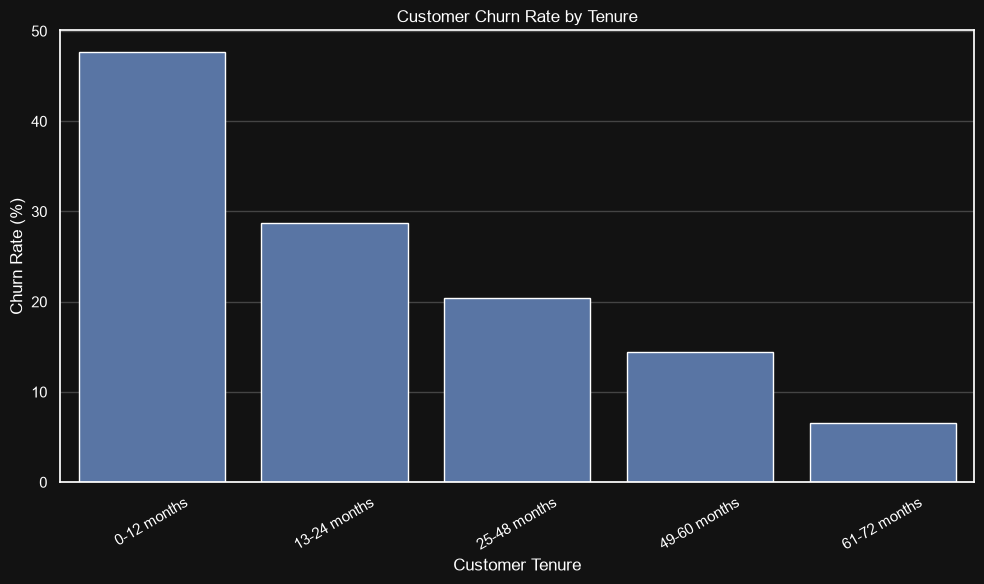

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns


sns.set_theme(style="darkgrid", context="notebook")

plt.rcParams.update({
    "figure.facecolor": "#121212",
    "axes.facecolor": "#121212",
    "axes.labelcolor": "white",
    "text.color": "white",
    "xtick.color": "white",
    "ytick.color": "white",
    "axes.edgecolor": "white",
    "grid.color": "#444444"
})

plt.figure(figsize=(10,6))

sns.barplot(
    x = tenure_churn.index,
    y = tenure_churn.values
)
plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Customer Tenure")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=30)
plt.tight_layout()

plt.show()

Contract
Month-to-month    42.709677
One year          11.277174
Two year           2.848665
Name: Churn, dtype: float64


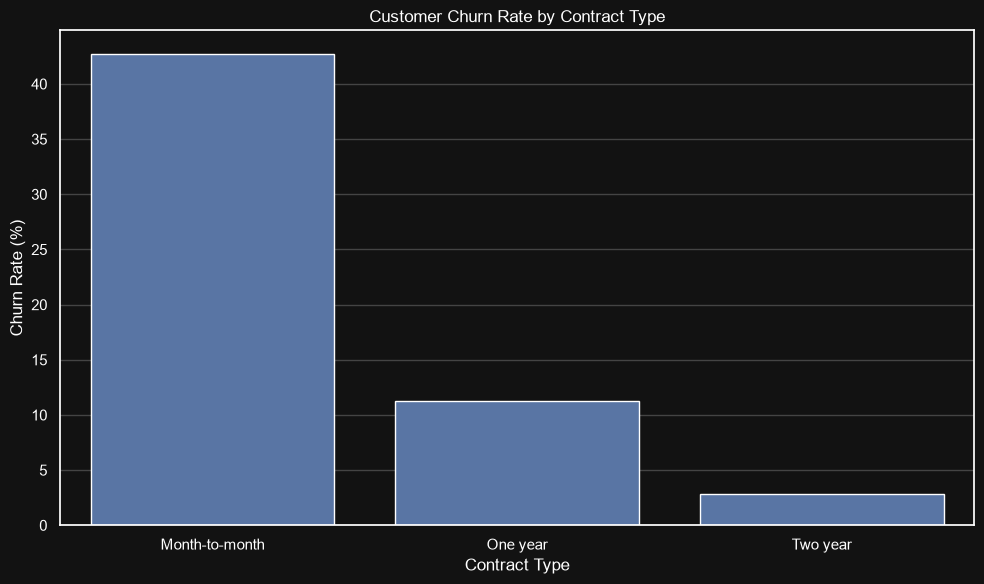

In [38]:
contract_churn = df.groupby(
    "Contract"
)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(contract_churn.sort_values(ascending=False))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values
)

plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.tight_layout()
plt.show()

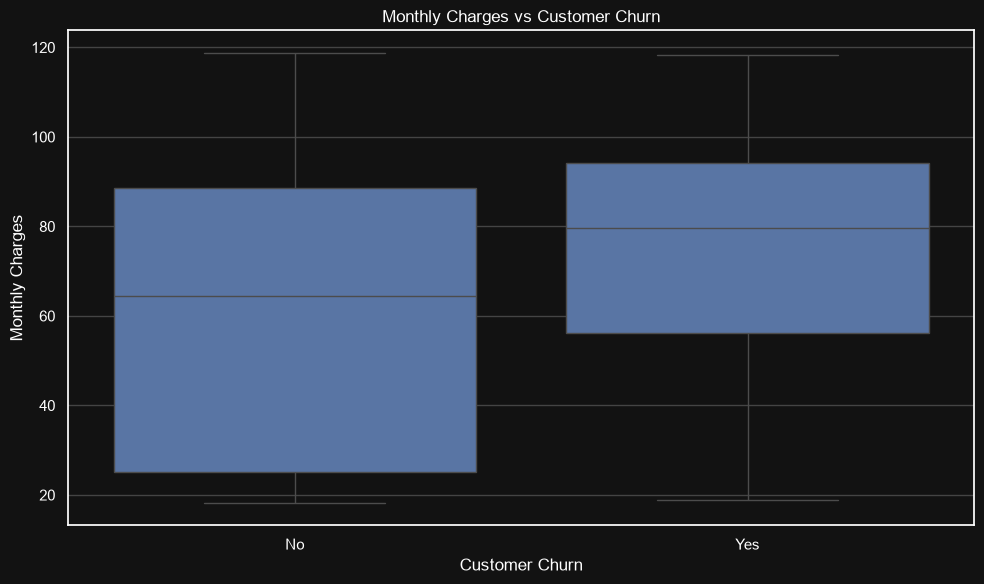

In [39]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Churn",
    y="MonthlyCharges"
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [40]:
monthly_stats = df.groupby("Churn")["MonthlyCharges"].describe()

print(monthly_stats)

        count       mean        std    min    25%    50%     75%     max
Churn                                                                   
No     5163.0  61.307408  31.094557  18.25  25.10  64.45  88.475  118.75
Yes    1869.0  74.441332  24.666053  18.85  56.15  79.65  94.200  118.35


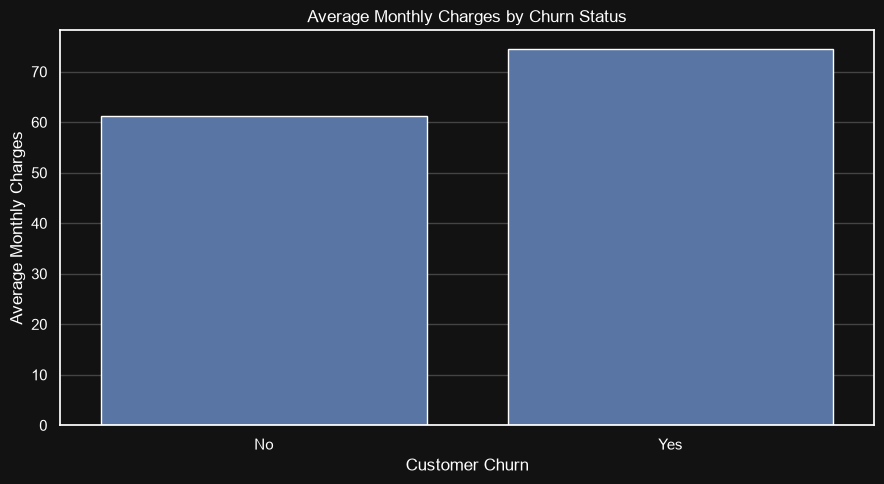

In [41]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Churn",
    y="MonthlyCharges",
    estimator="mean",
    errorbar=None
)

plt.title("Average Monthly Charges by Churn Status")
plt.xlabel("Customer Churn")
plt.ylabel("Average Monthly Charges")

plt.tight_layout()
plt.show()

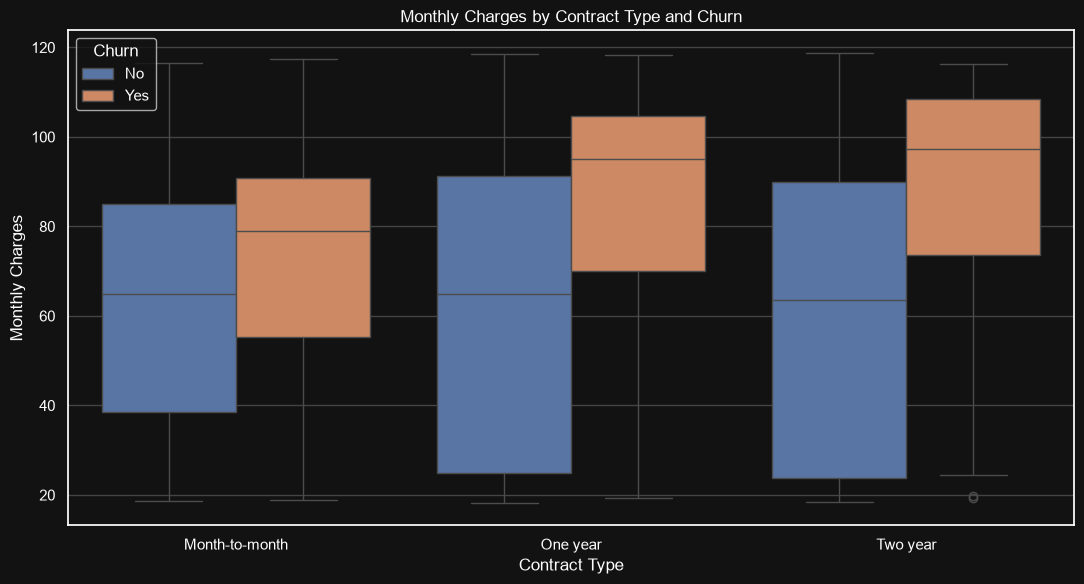

In [42]:
plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="Contract",
    y="MonthlyCharges",
    hue="Churn"
)

plt.title("Monthly Charges by Contract Type and Churn")
plt.xlabel("Contract Type")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

In [43]:
df["ChargeGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 100, 120],
    labels=["Low", "Medium", "High", "Very High"]
)

In [44]:
charge_contract_churn = df.pivot_table(
    index="Contract",
    columns="ChargeGroup",
    values="Churn",
    aggfunc=lambda x: (x == "Yes").mean() * 100,
    observed=False
)

print(charge_contract_churn.round(2))

ChargeGroup       Low  Medium   High  Very High
Contract                                       
Month-to-month  24.29   35.33  53.19      50.00
One year         3.12    7.82  12.84      24.91
Two year         0.78    2.14   3.03       7.54


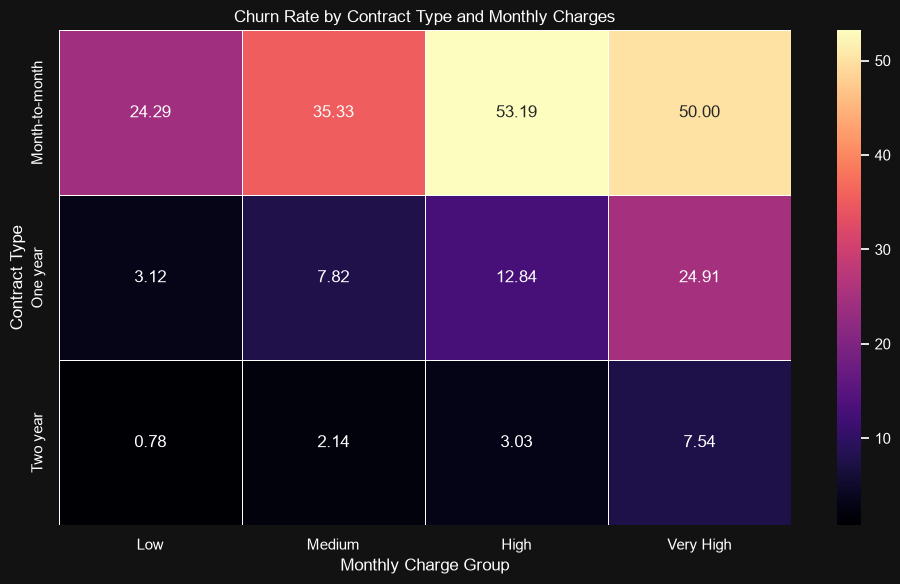

In [45]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    charge_contract_churn,
    annot=True,
    fmt=".2f",
    cmap="magma",
    linewidths=0.5
)

plt.title("Churn Rate by Contract Type and Monthly Charges")
plt.xlabel("Monthly Charge Group")
plt.ylabel("Contract Type")

plt.tight_layout()
plt.show()

In [46]:
# Filter month-to-month customers
monthly_customers = df[
    df["Contract"] == "Month-to-month"
]

# Compare customers who stayed and churned
monthly_analysis = monthly_customers.groupby("Churn").agg(
    customer_count=("Churn", "count"),
    avg_tenure=("tenure", "mean"),
    avg_monthly_charges=("MonthlyCharges", "mean"),
    avg_total_charges=("TotalCharges", "mean")
)

print(monthly_analysis.round(2))

       customer_count  avg_tenure  avg_monthly_charges  avg_total_charges
Churn                                                                    
No               2220       21.03                61.46            1521.93
Yes              1655       14.02                73.02            1164.46


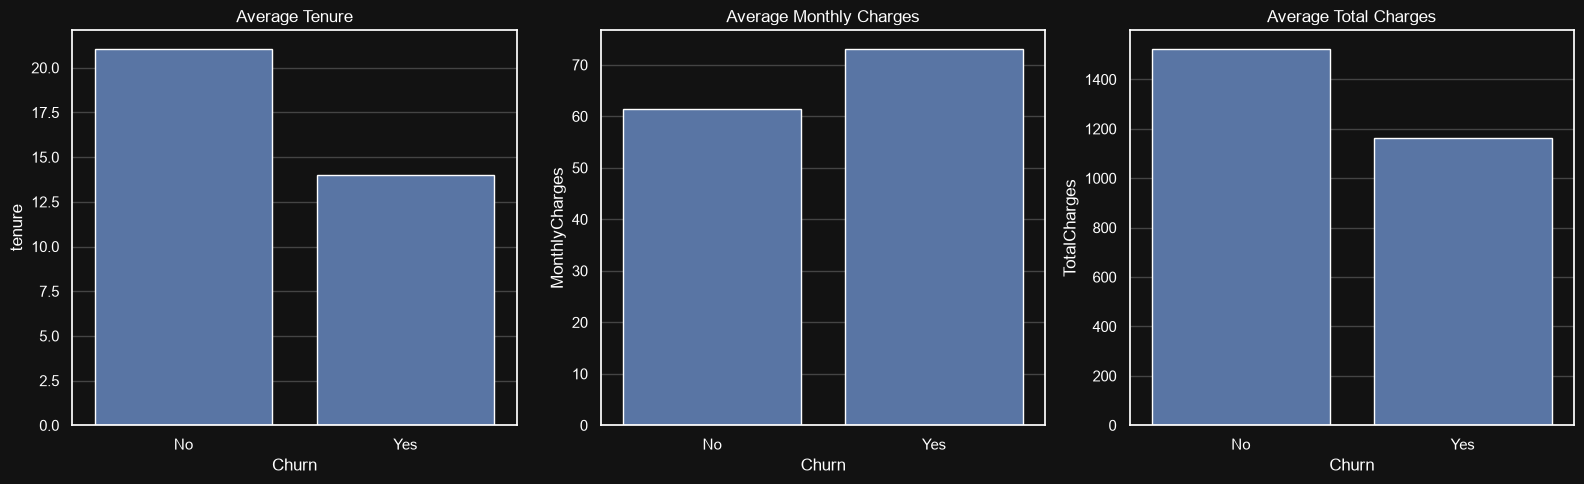

In [47]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.barplot(
    data=monthly_customers,
    x="Churn",
    y="tenure",
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Average Tenure")

sns.barplot(
    data=monthly_customers,
    x="Churn",
    y="MonthlyCharges",
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Average Monthly Charges")

sns.barplot(
    data=monthly_customers,
    x="Churn",
    y="TotalCharges",
    estimator="mean",
    errorbar=None,
    ax=axes[2]
)
axes[2].set_title("Average Total Charges")

plt.tight_layout()
plt.show()

In [48]:
payment_churn = monthly_customers.groupby(
    "PaymentMethod"
)["Churn"].apply(
    lambda x: (x == "Yes").mean() * 100
)

print(payment_churn.sort_values(ascending=False).round(2))

PaymentMethod
Electronic check             53.73
Bank transfer (automatic)    34.13
Credit card (automatic)      32.78
Mailed check                 31.58
Name: Churn, dtype: float64


In [49]:
payment_analysis = monthly_customers.groupby(
    ["PaymentMethod", "Churn"]
).agg(
    customer_count=("Churn", "count"),
    avg_monthly_charges=("MonthlyCharges", "mean"),
    avg_tenure=("tenure", "mean")
)

print(payment_analysis.round(2))

                                 customer_count  avg_monthly_charges  \
PaymentMethod             Churn                                        
Bank transfer (automatic) No                388                65.82   
                          Yes               201                75.38   
Credit card (automatic)   No                365                64.15   
                          Yes               178                74.92   
Electronic check          No                856                71.75   
                          Yes               994                77.78   
Mailed check              No                611                42.68   
                          Yes               282                53.35   

                                 avg_tenure  
PaymentMethod             Churn              
Bank transfer (automatic) No          27.86  
                          Yes         19.21  
Credit card (automatic)   No          25.81  
                          Yes         20.16  
Ele

In [50]:
monthly_customers.groupby("PaymentMethod")["tenure"].mean().sort_values()

PaymentMethod
Mailed check                 10.042553
Electronic check             17.971351
Credit card (automatic)      23.955801
Bank transfer (automatic)    24.904924
Name: tenure, dtype: float64

In [51]:
#model evaluation in classification treshold analysis

y_prob = rf_pipeline.predict_proba(X_test)[:,1]

#display

print(y_prob[:10])

print(rf_pipeline.classes_)

[0.005      0.885      0.02       0.08533333 0.26       0.4
 0.04       0.355      0.87       0.02      ]
['No' 'Yes']


In [52]:
#let't change the tresholds
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    # Convert probabilities into class predictions
    y_pred_threshold = np.where(y_prob >= threshold, "Yes", "No")

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", round(accuracy_score(y_test, y_pred_threshold), 3))
    print("Precision:", round(precision_score(y_test, y_pred_threshold, pos_label="Yes"), 3))
    print("Recall:", round(recall_score(y_test, y_pred_threshold, pos_label="Yes"), 3))
    print("F1:", round(f1_score(y_test, y_pred_threshold, pos_label="Yes"), 3))
    print("Confusion matrix:")
    print(confusion_matrix(y_test, y_pred_threshold))


Threshold: 0.3
Accuracy: 0.679
Precision: 0.445
Recall: 0.84
F1: 0.582
Confusion matrix:
[[642 391]
 [ 60 314]]

Threshold: 0.5
Accuracy: 0.761
Precision: 0.543
Recall: 0.647
F1: 0.59
Confusion matrix:
[[829 204]
 [132 242]]

Threshold: 0.7
Accuracy: 0.787
Precision: 0.653
Recall: 0.422
F1: 0.513
Confusion matrix:
[[949  84]
 [216 158]]


In [53]:
#hyperparameter

# n_estimators: number of decision trees.
# max_depth: maximum depth of each tree
# min_samples_split: minimum samples required to split a node.
# min_samples_leaf: minimum samples required at a leaf.


from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [5, 7, 10, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4]
}

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(...))
])

In [54]:
from sklearn.metrics import make_scorer, recall_score

recall_score = make_scorer(recall_score, pos_label = "Yes")


grid_search = GridSearchCV(
    estimator= rf_pipeline,
    param_grid=  param_grid,
    scoring = recall_score,
    cv =5,
    n_jobs=-1,
    verbose= 1
)

grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 108 candidates, totalling 540 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...s=Ellipsis))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__max_depth': [5, 7, ...], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], 'classifier__n_estimators': [100, 200, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",make_scorer(r...pos_label=Yes)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` paramete

In [55]:
print("Best parameters:", grid_search.best_params_)
print("Best CV recall:", grid_search.best_score_)

Best parameters: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 10, 'classifier__n_estimators': 200}
Best CV recall: 0.5257525083612039


In [56]:
# An important observation: our earlier Random Forest achieved approximately 64.1% cross-validation recall, while GridSearchCV selected a configuration with 52.71%.

# That means tuning for recall did not improve our previous result. We should investigate this rather than assume that more trees
# or greater depth automatically produce a better model.

In [57]:
#3. Next: Evaluate the tuned model on the test set

best_rf = grid_search.best_estimator_

y_pred_tuned = best_rf.predict(X_test)

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_tuned))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_tuned))

              precision    recall  f1-score   support

          No       0.83      0.89      0.86      1033
         Yes       0.63      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407

Confusion matrix:
[[920 113]
 [185 189]]


In [58]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Get churn probabilities from the tuned model
y_prob_tuned = best_rf.predict_proba(X_test)[:, 1]

# Compare thresholds
for threshold in [0.3, 0.4, 0.5]:

    y_pred_threshold = np.where(
        y_prob_tuned >= threshold, "Yes", "No"
    )

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(
        precision_score(y_test, y_pred_threshold, pos_label="Yes"), 3
    ))
    print("Recall:", round(
        recall_score(y_test, y_pred_threshold, pos_label="Yes"), 3
    ))
    print("F1:", round(
        f1_score(y_test, y_pred_threshold, pos_label="Yes"), 3
    ))


Threshold: 0.3
Precision: 0.514
Recall: 0.791
F1: 0.623

Threshold: 0.4
Precision: 0.568
Recall: 0.639
F1: 0.601

Threshold: 0.5
Precision: 0.626
Recall: 0.505
F1: 0.559


In [59]:
from sklearn.model_selection import train_test_split

X_train_sub, X_val, y_train_sub, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training subset:", X_train_sub.shape)
print("Validation set:", X_val.shape)

Training subset: (4500, 19)
Validation set: (1125, 19)


In [60]:
best_rf.fit(X_train_sub, y_train_sub)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](19,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'TotalCharges']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,19
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remain

In [61]:
y_val_prob = best_rf.predict_proba(X_val)[:, 1]

print(y_val_prob[:10])

[0.53951758 0.15550855 0.12482086 0.05095256 0.09107713 0.33787116
 0.00565835 0.19097359 0.10966653 0.07009571]


In [62]:
thresholds = [0.3, 0.4, 0.5]

for threshold in thresholds:

    y_val_pred = np.where(
        y_val_prob >= threshold, "Yes", "No"
    )

    precision = precision_score(
        y_val, y_val_pred, pos_label="Yes"
    )

    recall = recall_score(
        y_val, y_val_pred, pos_label="Yes"
    )

    f1 = f1_score(
        y_val, y_val_pred, pos_label="Yes"
    )

    print(f"\nThreshold: {threshold}")
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1:", round(f1, 3))


Threshold: 0.3
Precision: 0.53
Recall: 0.729
F1: 0.614

Threshold: 0.4
Precision: 0.585
Recall: 0.612
F1: 0.598

Threshold: 0.5
Precision: 0.643
Recall: 0.482
F1: 0.551


In [63]:
# Retrain using all training data
best_rf.fit(X_train, y_train)

# Generate probabilities on the untouched test set
y_test_prob = best_rf.predict_proba(X_test)[:, 1]

# Apply the selected threshold
y_pred_final = np.where(y_test_prob >= 0.3, "Yes", "No")

In [64]:
print(classification_report(y_test, y_pred_final))

print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_final))

              precision    recall  f1-score   support

          No       0.90      0.73      0.81      1033
         Yes       0.51      0.78      0.62       374

    accuracy                           0.75      1407
   macro avg       0.71      0.76      0.71      1407
weighted avg       0.80      0.75      0.76      1407

Confusion matrix:
[[757 276]
 [ 82 292]]


In [66]:
import shap
import matplotlib.pyplot as plt



best_rf



# Extract the trained Random Forest classifier
rf_model = best_rf.named_steps["classifier"]

# Transform the training data using the fitted preprocessor
X_train_transformed = best_rf.named_steps["preprocessor"].transform(X_train)

# Get the transformed feature names
feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()

print("Transformed shape:", X_train_transformed.shape)
print("Number of feature names:", len(feature_names))

c:\Users\felix\Desktop\models\Churn-model\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Transformed shape: (5625, 45)
Number of feature names: 45


In [67]:
explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_train_transformed)
print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(5625, 45, 2)


(5625, 45)


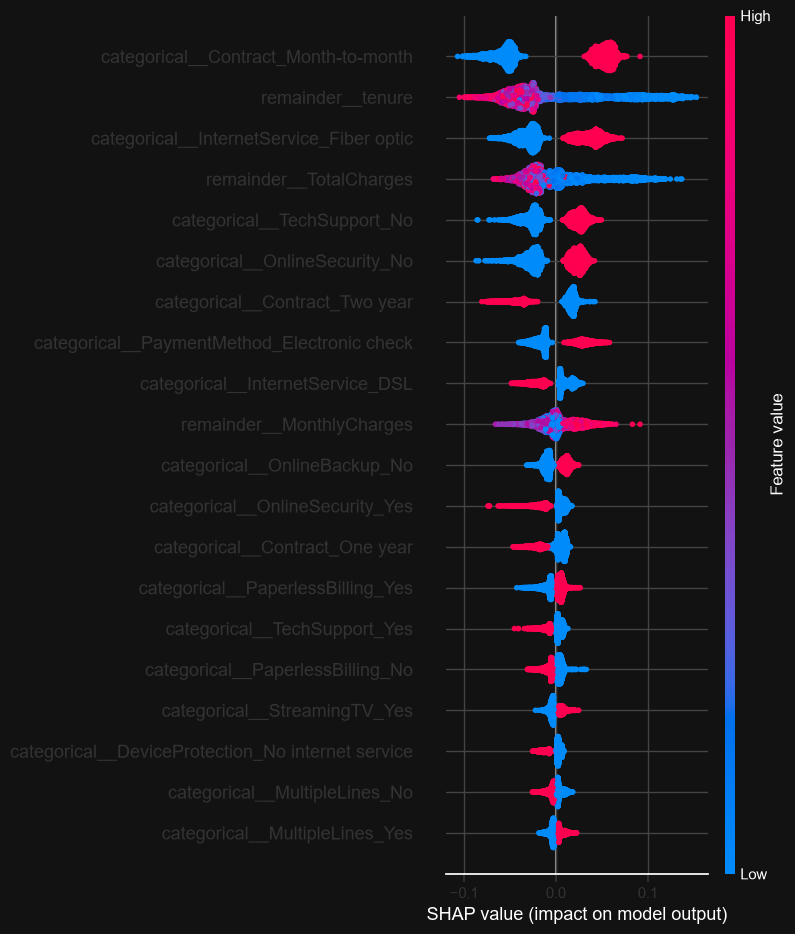

In [68]:
shap_values_yes = shap_values[:, :, 1]

print(shap_values_yes.shape)

shap.summary_plot(
    shap_values_yes,
    X_train_transformed,
    feature_names=feature_names
)

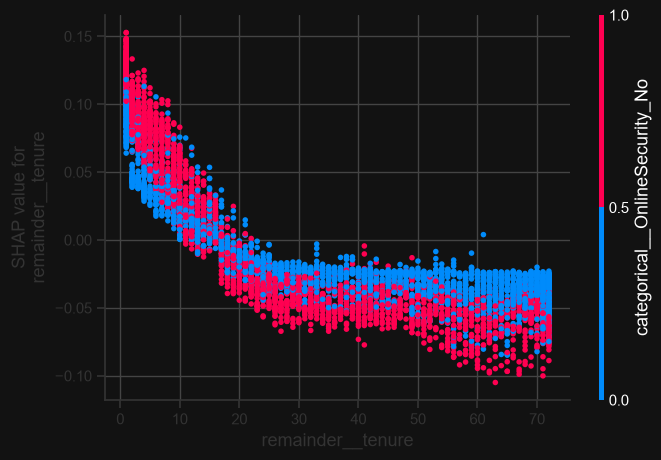

In [69]:
shap.dependence_plot(
    "remainder__tenure",
    shap_values_yes,
    X_train_transformed,
    feature_names=feature_names
)

In [ ]:
sample_index = 0

# Get the selected customer's transformed features
sample = X_train_transformed[sample_index]

# Convert sparse data to a dense array if necessary
if hasattr(sample, "toarray"):
    sample = sample.toarray()

sample = np.asarray(sample).flatten()

# Get SHAP values for this customer and churn class
sample_shap = shap_values_yes[sample_index]

# Get the baseline SHAP value for churn
base_value = explainer.expected_value[1]

print("Actual class:", y_train.iloc[sample_index])
print("Predicted churn probability:",
      best_rf.predict_proba(X_train.iloc[[sample_index]])[0, 1])


Actual class: No
Predicted churn probability: 0.04989275246098211


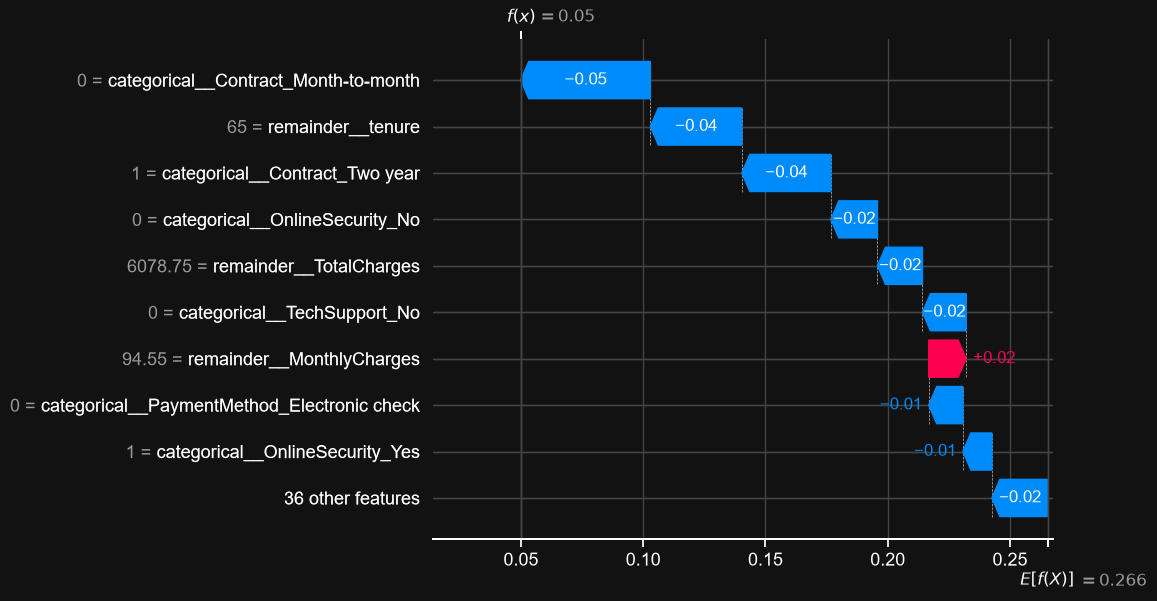

In [71]:
explanation = shap.Explanation(
    values=sample_shap,
    base_values=base_value,
    data=sample,
    feature_names=feature_names
)

shap.plots.waterfall(explanation)

## saving the model


In [72]:
import joblib

#model artifact

model_artifact = {
    "model": best_rf,
    "threshold": 0.3,
    "target_class": "Yes",
    "feature_columns": X_train.columns.tolist()
}


joblib.dump(model_artifact, "churn_model.joblib")

['churn_model.joblib']

In [73]:
loaded_artifact = joblib.load("churn_model.joblib")

loaded_model = loaded_artifact["model"]
threshold = loaded_artifact["threshold"]

print("Threshold:", threshold)
print("Features:", len(loaded_artifact["feature_columns"]))

Threshold: 0.3
Features: 19


In [75]:
#lets verify the loaded model predictions

# Select 10 customers from the test set
sample_customers = X_test.iloc[:10]

# Predictions from the original model
original_predictions = best_rf.predict_proba(sample_customers)[:, 1]

# Predictions from the loaded model
loaded_predictions = loaded_model.predict_proba(sample_customers)[:, 1]

# Compare the results
print(np.allclose(original_predictions, loaded_predictions))

True
